<a href="https://colab.research.google.com/github/Jerefilms/DEEP-LEARNING/blob/main/notebook1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dispositivo en uso: cpu
Descargando dataset LFW...
Total de imágenes cargadas: 5985
Forma de un batch: torch.Size([64, 3, 64, 64])


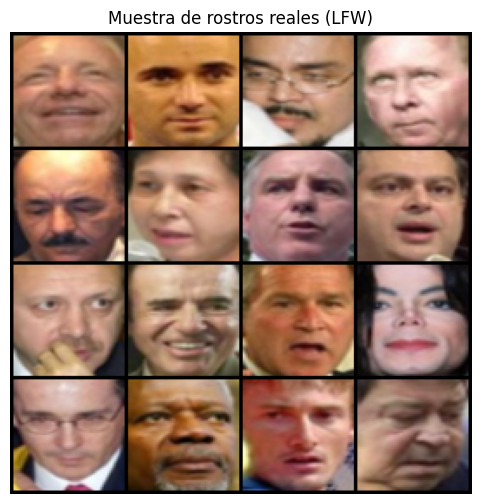

Iniciando entrenamiento...
Época [1/30] | Pérdida D: 1.1992 | Pérdida G: 11.0706


KeyboardInterrupt: 

In [1]:

# NOTEBOOK 1: GENERACIÓN DE ROSTROS HUMANOS

import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import torchvision.transforms as transforms
import torchvision.utils as vutils
from sklearn.datasets import fetch_lfw_people

# Fijar semillas
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Seleccionar GPU si está disponible en Colab; de lo contrario usar CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo en uso:", device)

#hiperparametros
BATCH_SIZE = 64
IMAGE_SIZE = 64
CHANNELS = 3
LATENT_DIM = 100
NGF = 64
NDF = 64
LR = 0.0002
BETA1 = 0.5
EPOCHS = 30

#dataset
print("Descargando dataset LFW...")
lfw_data = fetch_lfw_people(min_faces_per_person=5, resize=0.5, color=True)
imagenes_raw = lfw_data.images  # Arreglo NumPy con rostros a color

# Transformaciones: redimensionar a 64x64, convertir a tensor
transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

tensores = []
for img in imagenes_raw:

    img_uint8 = (img * 255).astype(np.uint8) if img.max() <= 1.0 else img.astype(np.uint8)
    tensores.append(transform(img_uint8))

dataset = TensorDataset(torch.stack(tensores))
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)

print(f"Total de imágenes cargadas: {len(dataset)}")
lote_ejemplo = next(iter(dataloader))[0]
print("Forma de un batch:", lote_ejemplo.shape)

# Visualizar 16 rostros reales del dataset
plt.figure(figsize=(6, 6))
plt.axis("off")
plt.title("Muestra de rostros reales (LFW)")
plt.imshow(np.transpose(vutils.make_grid(lote_ejemplo[:16], nrow=4, padding=2, normalize=True), (1, 2, 0)))
plt.show()

#inciiar en pesos
# Inicializa capas convolucionales
def weights_init(m):
    classname = m.__class__.__name__
    if classname.find("Conv") != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif classname.find("BatchNorm") != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)

#arquitectura de generador

class Generator(nn.Module):
    def __init__(self):
        super(Generator, self).__init__()
        self.main = nn.Sequential(
            # (100, 1, 1) -> (NGF*8, 4, 4)
            nn.ConvTranspose2d(LATENT_DIM, NGF * 8, kernel_size=4, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(NGF * 8),
            nn.ReLU(True),

            # (NGF*8, 4, 4) -> (NGF*4, 8, 8)
            nn.ConvTranspose2d(NGF * 8, NGF * 4, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(NGF * 4),
            nn.ReLU(True),

            # (NGF*4, 8, 8) -> (NGF*2, 16, 16)
            nn.ConvTranspose2d(NGF * 4, NGF * 2, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(NGF * 2),
            nn.ReLU(True),

            # (NGF*2, 16, 16) -> (NGF, 32, 32)
            nn.ConvTranspose2d(NGF * 2, NGF, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(NGF),
            nn.ReLU(True),

            # (NGF, 32, 32) -> (3, 64, 64) con salida en [-1, 1] gracias a Tanh
            nn.ConvTranspose2d(NGF, CHANNELS, kernel_size=4, stride=2, padding=1, bias=False),
            nn.Tanh()
        )

    def forward(self, input_z):
        return self.main(input_z)

#arquitectura discriminador

class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator, self).__init__()
        self.main = nn.Sequential(
            # (3, 64, 64) -> (NDF, 32, 32) sin BatchNorm en la capa de entrada
            nn.Conv2d(CHANNELS, NDF, kernel_size=4, stride=2, padding=1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),

            # (NDF, 32, 32) -> (NDF*2, 16, 16)
            nn.Conv2d(NDF, NDF * 2, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(NDF * 2),
            nn.LeakyReLU(0.2, inplace=True),

            # (NDF*2, 16, 16) -> (NDF*4, 8, 8)
            nn.Conv2d(NDF * 2, NDF * 4, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(NDF * 4),
            nn.LeakyReLU(0.2, inplace=True),

            # (NDF*4, 8, 8) -> (NDF*8, 4, 4)
            nn.Conv2d(NDF * 4, NDF * 8, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(NDF * 8),
            nn.LeakyReLU(0.2, inplace=True),

            # (NDF*8, 4, 4) -> (1, 1, 1) -> escalar entre 0 y 1 con Sigmoid
            nn.Conv2d(NDF * 8, 1, kernel_size=4, stride=1, padding=0, bias=False),
            nn.Sigmoid()
        )

    def forward(self, input_img):
        return self.main(input_img).view(-1)

# Crear instancias de Generador
netG = Generator().to(device)
netG.apply(weights_init)

netD = Discriminator().to(device)
netD.apply(weights_init)

#perdida
criterion = nn.BCELoss()
fixed_noise = torch.randn(16, LATENT_DIM, 1, 1, device=device)

real_label = 1.0
fake_label = 0.0

optimizerD = optim.Adam(netD.parameters(), lr=LR, betas=(BETA1, 0.999))
optimizerG = optim.Adam(netG.parameters(), lr=LR, betas=(BETA1, 0.999))

#entrenamiento adversasrial
G_losses = []
D_losses = []

print("Iniciando entrenamiento...")
for epoch in range(1, EPOCHS + 1):
    for i, (data,) in enumerate(dataloader):

        netD.zero_grad()


        real_cpu = data.to(device)
        b_size = real_cpu.size(0)
        label = torch.full((b_size,), real_label, dtype=torch.float, device=device)
        output_real = netD(real_cpu)
        errD_real = criterion(output_real, label)
        errD_real.backward()


        noise = torch.randn(b_size, LATENT_DIM, 1, 1, device=device)
        fake = netG(noise)
        label.fill_(fake_label)
        output_fake = netD(fake.detach())
        errD_fake = criterion(output_fake, label)
        errD_fake.backward()

        errD = errD_real + errD_fake
        optimizerD.step()


        netG.zero_grad()
        label.fill_(real_label)
        output_gen = netD(fake)
        errG = criterion(output_gen, label)
        errG.backward()
        optimizerG.step()


        G_losses.append(errG.item())
        D_losses.append(errD.item())

    if epoch % 5 == 0 or epoch == 1:
        print(f"Época [{epoch}/{EPOCHS}] | Pérdida D: {errD.item():.4f} | Pérdida G: {errG.item():.4f}")

#graficar perdidas
plt.figure(figsize=(10, 4))
plt.title("Pérdidas del Generador y Discriminador durante el entrenamiento")
plt.plot(G_losses, label="Generador (G)")
plt.plot(D_losses, label="Discriminador (D)")
plt.xlabel("Iteraciones")
plt.ylabel("Pérdida (BCE)")
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

# Generar imágenes finales usando el ruido fijo
netG.eval()
with torch.no_grad():
    fake_samples = netG(fixed_noise).detach().cpu()

plt.figure(figsize=(6, 6))
plt.axis("off")
plt.title(f"Rostros generados por DCGAN (Época {EPOCHS})")
plt.imshow(np.transpose(vutils.make_grid(fake_samples, nrow=4, padding=2, normalize=True), (1, 2, 0)))
plt.show()